# Nhận dạng chữ số viết tay với MNIST

## Bài 7

### Yêu cầu

Xây dựng ứng dụng nhận dạng chữ số viết tay dựa trên MNIST theo yêu cầu trang 27. Biểu diễn mẫu huấn luyện thuộc các lớp 0, 1, 2, 3; chuyển ảnh thành vector đầu vào; chia huấn luyện 80%, kiểm thử 20%; xây dựng cây theo entropy như hướng dẫn, dự đoán và đánh giá bằng báo cáo phân lớp, ma trận nhầm lẫn; xử lý ảnh chữ số viết tay và in kết quả nhận dạng.

### Dữ liệu và phương pháp

MNIST được lấy từ bốn tệp ảnh/nhãn liên kết tại https://github.com/cvdfoundation/mnist. Ảnh MNIST có kích thước 28×28, tương ứng vector 784 chiều, giá trị pixel 0–255. Ghép đầy đủ hai phần nguồn để áp dụng phép chia 80/20 của bài; không lấy mẫu rút gọn. Cây entropy có random_state=33; phép chia giữ shuffle=False theo hướng dẫn. Bốn ảnh minh họa lấy từ tập huấn luyện thực tế.

Ảnh chụp chữ số được chuyển xám, thu về 28×28, đảo màu, phân ngưỡng 110 và biểu diễn bằng mức 0/255 cùng miền với MNIST. Kích thước xử lý ảnh và vector được thống nhất với dữ liệu MNIST.

In [1]:
print("Đặng Ngọc Hiếu - 6451071024")

from pathlib import Path
from urllib.request import urlretrieve
import gzip
import struct
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from PIL import Image, ImageOps

ROOT = Path.cwd()
while not (ROOT / "datasets").is_dir():
    if (ROOT / "6451071024_Lab2" / "datasets").is_dir():
        ROOT = ROOT / "6451071024_Lab2"
        break
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Không tìm thấy thư mục datasets của LAB2.")
    ROOT = ROOT.parent
plt.rcParams["font.family"] = "DejaVu Sans"

# Bốn URL tải xuống được cung cấp trong trang cvdfoundation/mnist.
MNIST_DIR = ROOT / "datasets/digits/mnist"
MNIST_DIR.mkdir(parents=True, exist_ok=True)
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"
FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
         "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
for filename in FILES:
    destination = MNIST_DIR / filename
    if not destination.is_file():
        urlretrieve(BASE_URL + filename, destination)


Đặng Ngọc Hiếu - 6451071024


In [2]:
print("Đặng Ngọc Hiếu - 6451071024")

def read_images(path):
    with gzip.open(path, "rb") as stream:
        magic, count, rows, columns = struct.unpack(">IIII", stream.read(16))
        pixels = np.frombuffer(stream.read(), dtype=np.uint8)
    if magic != 2051 or (rows, columns) != (28, 28):
        raise ValueError("Tệp ảnh phải đúng định dạng IDX của MNIST 28×28.")
    if pixels.size != count * rows * columns:
        raise ValueError("Số byte ảnh không khớp header IDX.")
    return pixels.reshape(count, rows, columns)

def read_labels(path):
    with gzip.open(path, "rb") as stream:
        magic, count = struct.unpack(">II", stream.read(8))
        labels = np.frombuffer(stream.read(), dtype=np.uint8)
    if magic != 2049 or labels.size != count:
        raise ValueError("Tệp nhãn không đúng định dạng IDX của MNIST.")
    return labels

source_train_images = read_images(MNIST_DIR / FILES[0])
source_train_labels = read_labels(MNIST_DIR / FILES[1])
source_test_images = read_images(MNIST_DIR / FILES[2])
source_test_labels = read_labels(MNIST_DIR / FILES[3])
for images_part, labels_part in [(source_train_images, source_train_labels),
                                (source_test_images, source_test_labels)]:
    if len(images_part) != len(labels_part):
        raise ValueError("Số ảnh và số nhãn MNIST không khớp.")
images = np.concatenate([source_train_images, source_test_images], axis=0)
labels = np.concatenate([source_train_labels, source_test_labels])
if not np.array_equal(np.unique(labels), np.arange(10)):
    raise ValueError("MNIST cần có các nhãn chữ số từ 0 đến 9.")
print("Số mẫu của hai phần nguồn:", len(source_train_images), len(source_test_images))
print("Tổng dữ liệu ảnh sử dụng:", images.shape)
print("Miền giá trị pixel:", images.min(), images.max())


Đặng Ngọc Hiếu - 6451071024
Số mẫu của hai phần nguồn: 60000 10000
Tổng dữ liệu ảnh sử dụng: (70000, 28, 28)
Miền giá trị pixel: 0 255


Đặng Ngọc Hiếu - 6451071024
Dữ liệu sau vector hóa: (70000, 784)
Số mẫu huấn luyện / kiểm thử: 56000 14000


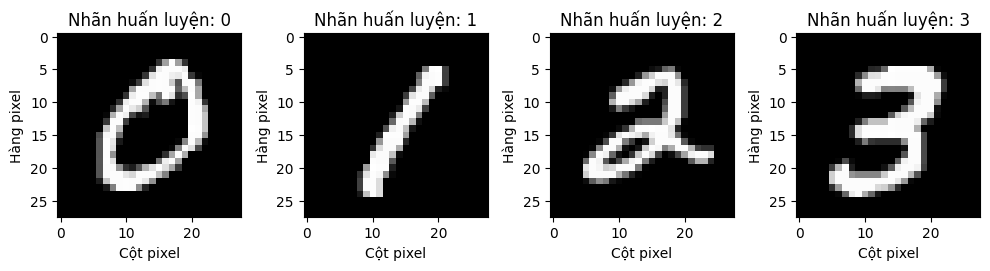

In [3]:
print("Đặng Ngọc Hiếu - 6451071024")

data = images.reshape(len(images), 28 * 28)
X_train, X_test, y_train, y_test = train_test_split(
    data, labels, test_size=0.2, shuffle=False)
print("Dữ liệu sau vector hóa:", data.shape)
print("Số mẫu huấn luyện / kiểm thử:", len(X_train), len(X_test))

# Lấy đúng bốn mẫu từ tập huấn luyện, mỗi mẫu thuộc một lớp 0–3.
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for label, ax in enumerate(axes):
    index = np.flatnonzero(y_train == label)[0]
    ax.imshow(X_train[index].reshape(28, 28), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Nhãn huấn luyện: {label}")
    ax.set_xlabel("Cột pixel")
    ax.set_ylabel("Hàng pixel")
plt.tight_layout()
plt.show()
plt.close(fig)


Đặng Ngọc Hiếu - 6451071024


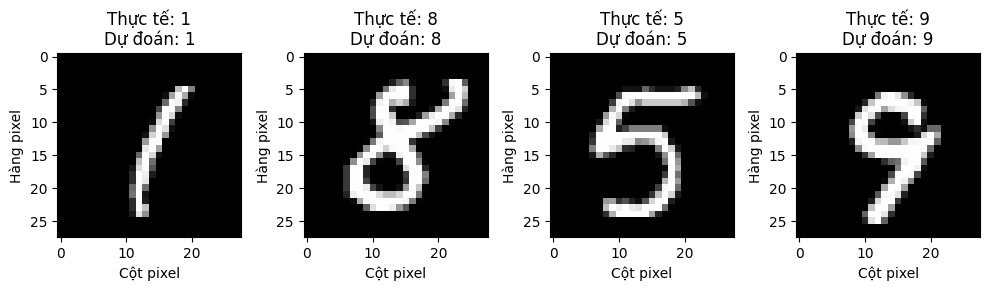

In [4]:
print("Đặng Ngọc Hiếu - 6451071024")

classifier = DecisionTreeClassifier(criterion="entropy", random_state=33)
classifier.fit(X_train, y_train)
predicted = classifier.predict(X_test)
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for index, ax in enumerate(axes):
    ax.imshow(X_test[index].reshape(28, 28), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Thực tế: {y_test[index]}\nDự đoán: {predicted[index]}")
    ax.set_xlabel("Cột pixel")
    ax.set_ylabel("Hàng pixel")
plt.tight_layout()
plt.show()
plt.close(fig)


Đặng Ngọc Hiếu - 6451071024
Accuracy: 0.8902857142857142
              precision    recall  f1-score   support

           0     0.9372    0.9345    0.9358      1373
           1     0.9548    0.9688    0.9617      1569
           2     0.8876    0.8783    0.8830      1430
           3     0.8369    0.8570    0.8469      1413
           4     0.8858    0.8852    0.8855      1376
           5     0.8411    0.8236    0.8323      1253
           6     0.9122    0.9156    0.9139      1339
           7     0.9090    0.9299    0.9193      1483
           8     0.8640    0.8425    0.8531      1365
           9     0.8597    0.8499    0.8548      1399

    accuracy                         0.8903     14000
   macro avg     0.8888    0.8885    0.8886     14000
weighted avg     0.8901    0.8903    0.8901     14000



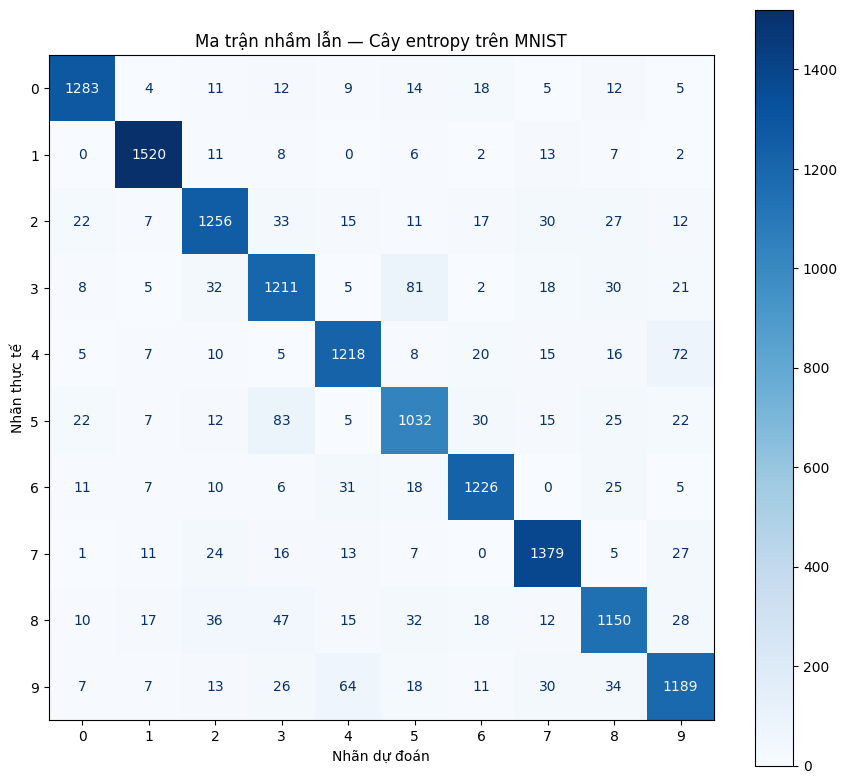

In [5]:
print("Đặng Ngọc Hiếu - 6451071024")

print("Accuracy:", accuracy_score(y_test, predicted))
# Quy ước chỉ số có mẫu số bằng 0 là 0; support vẫn thể hiện số mẫu thật.
print(classification_report(y_test, predicted, labels=np.arange(10),
    digits=4, zero_division=0))
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=np.arange(10),
    display_labels=np.arange(10), cmap="Blues", ax=ax)
ax.set_title("Ma trận nhầm lẫn — Cây entropy trên MNIST")
ax.set_xlabel("Nhãn dự đoán")
ax.set_ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()
plt.close(fig)


Đặng Ngọc Hiếu - 6451071024


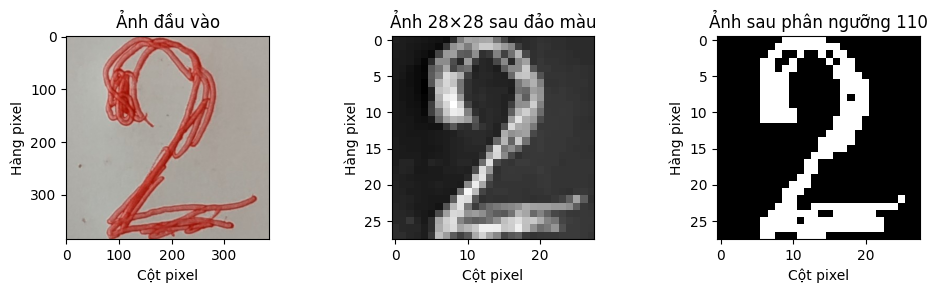

Kích thước vector đưa vào cây: (1, 784)
Miền pixel sau phân ngưỡng: 0 255
test_image_Bai7.jpg: chữ số dự đoán = 4


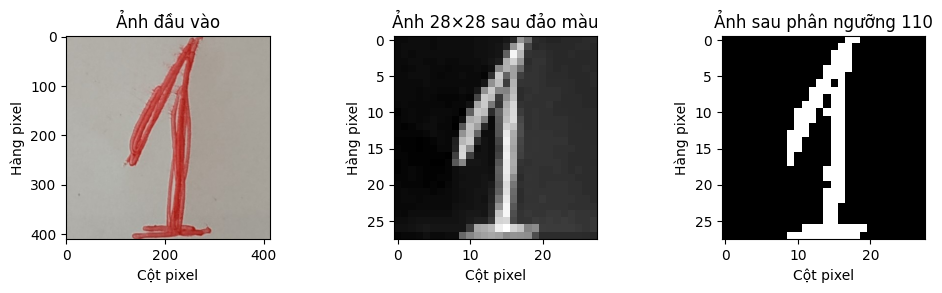

Kích thước vector đưa vào cây: (1, 784)
Miền pixel sau phân ngưỡng: 0 255
test_image_Bai7(1).jpg: chữ số dự đoán = 9
Kết quả nhận dạng ảnh chụp phụ thuộc nét viết, ánh sáng và phép thu nhỏ ảnh.


In [7]:
print("Đặng Ngọc Hiếu - 6451071024")

IMAGE_FILES = ["test_image_Bai7.jpg", "test_image_Bai7(1).jpg"]
THRESHOLD = 110
for filename in IMAGE_FILES:
    path = ROOT / "datasets/digits" / filename
    if not path.is_file():
        raise FileNotFoundError(f"Thiếu ảnh chữ số: {filename}")
    with Image.open(path) as source:
        original = source.convert("RGB")
    # Bù viền trắng để ảnh vuông mà không cắt nét chữ hoặc kéo méo ảnh.
    side = max(original.size)
    square = ImageOps.pad(original, (side, side), color="white")
    gray = square.convert("L").resize((28, 28))
    inverted = np.asarray(ImageOps.invert(gray))
    # Giữ ngưỡng 110, dùng mức 0/255 đúng miền pixel của MNIST.
    binary = np.where(inverted >= THRESHOLD, 255, 0).astype(np.uint8)
    vector = binary.reshape(1, 28 * 28)
    result = classifier.predict(vector)[0]
    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    for ax, image, title in zip(axes,
            [original, inverted, binary],
            ["Ảnh đầu vào", "Ảnh 28×28 sau đảo màu", "Ảnh sau phân ngưỡng 110"]):
        ax.imshow(image, cmap="gray")
        ax.set_title(title)
        ax.set_xlabel("Cột pixel")
        ax.set_ylabel("Hàng pixel")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    print("Kích thước vector đưa vào cây:", vector.shape)
    print("Miền pixel sau phân ngưỡng:", vector.min(), vector.max())
    print(f"{filename}: chữ số dự đoán = {result}")
print("Kết quả nhận dạng ảnh chụp phụ thuộc nét viết, ánh sáng và phép thu nhỏ ảnh.")
